# EPL rolling feature ablations: exploratory retrospective research

**2025/26 outcomes were inspected in the first experiment. This is not a fresh confirmatory holdout.** This executed notebook loads saved outputs only: it does not train, tune, calibrate or select a model. Current-club survivor bias and unverified quote/feature publication times remain. See `ablation_results/ABLATION_RESULTS.md`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
folder = "ablation_results"
candidates = [Path.cwd()/folder, Path.cwd()/'epl_modeling'/folder, Path.cwd()]
RESULTS = next((p for p in candidates if (p/'run_metadata.json').exists() and ((p/'classification_scores.parquet').exists() or (p/'classification_scores.csv').exists())), None)
if RESULTS is None:
    raise FileNotFoundError('Run the ablation experiment first, then open this notebook from epl_modeling or the project root.')
def table(name):
    p=RESULTS/(name+'.parquet')
    return pd.read_parquet(p) if p.exists() else pd.read_csv(RESULTS/(name+'.csv'))
metadata=json.loads((RESULTS/'run_metadata.json').read_text(encoding='utf-8'))
display({k:metadata.get(k) for k in ['study_status','run_date','data_snapshot_as_of','seed','common_sample_matches','first_experiment_preserved']})
display(table('chronological_roles'))

{'study_status': 'exploratory_retrospective_not_a_fresh_holdout',
 'run_date': '2026-10-13',
 'data_snapshot_as_of': '2026-10-06',
 'seed': 42,
 'common_sample_matches': 1470,
 'first_experiment_preserved': True}

,outer_season,role,seasons,n_matches,date_min,date_max,complete_history_matches
0,2022-23,train,"2016-17,2017-18,2018-19,2019-20",1264,2016-08-13,2020-07-26,358
1,2022-23,tune,2020-21,338,2020-09-12,2021-05-23,107
2,2022-23,calibration,2021-22,338,2021-08-13,2022-05-22,129
3,2022-23,evaluation,2022-23,368,2022-08-05,2023-05-28,153
4,2023-24,train,"2016-17,2017-18,2018-19,2019-20,2020-21",1602,2016-08-13,2021-05-23,465
5,2023-24,tune,2021-22,338,2021-08-13,2022-05-22,129
6,2023-24,calibration,2022-23,368,2022-08-05,2023-05-28,153
7,2023-24,evaluation,2023-24,360,2023-08-11,2024-05-19,205
8,2024-25,train,"2016-17,2017-18,2018-19,2019-20,2020-21,2021-22",1940,2016-08-13,2022-05-22,594
9,2024-25,tune,2022-23,368,2022-08-05,2023-05-28,153


## Pooled probability quality
Lower log loss/Brier are better. Pooled ECE is recomputed from pooled probabilities, not an average of seasonal ECE. All rankings are descriptive.

,outer_season,scope,feature_group,model_type,n_matches,accuracy,classwise_ece_10,classwise_ece_5,classwise_ece_15,log_loss,brier_score
96,pooled,common_odds_matches,market_only,baseline,1470,0.544218,0.017716,0.014935,0.019931,0.966170,0.574258
97,pooled,common_odds_matches,market_only,market_temperature,1470,0.544218,0.019741,0.014829,0.019542,0.967069,0.574974
93,pooled,common_odds_matches,team_player,market_residual,1470,0.541497,0.021578,0.013788,0.030280,0.969294,0.575101
95,pooled,common_odds_matches,combined,market_residual,1470,0.542177,0.020327,0.013814,0.028449,0.969705,0.575237
91,pooled,common_odds_matches,team_xg,market_residual,1470,0.542177,0.030896,0.014072,0.025758,0.970139,0.575751
89,pooled,common_odds_matches,team,market_residual,1470,0.540816,0.022575,0.014521,0.029714,0.970150,0.575811
90,pooled,common_odds_matches,team_xg,logistic,1470,0.533333,0.025505,0.009972,0.033244,0.984052,0.586560
94,pooled,common_odds_matches,combined,logistic,1470,0.531293,0.030095,0.015502,0.032080,0.984539,0.586496
88,pooled,common_odds_matches,team,logistic,1470,0.529252,0.021664,0.011291,0.028689,0.987567,0.588866
92,pooled,common_odds_matches,team_player,logistic,1470,0.525170,0.027535,0.013903,0.025197,0.987570,0.588537


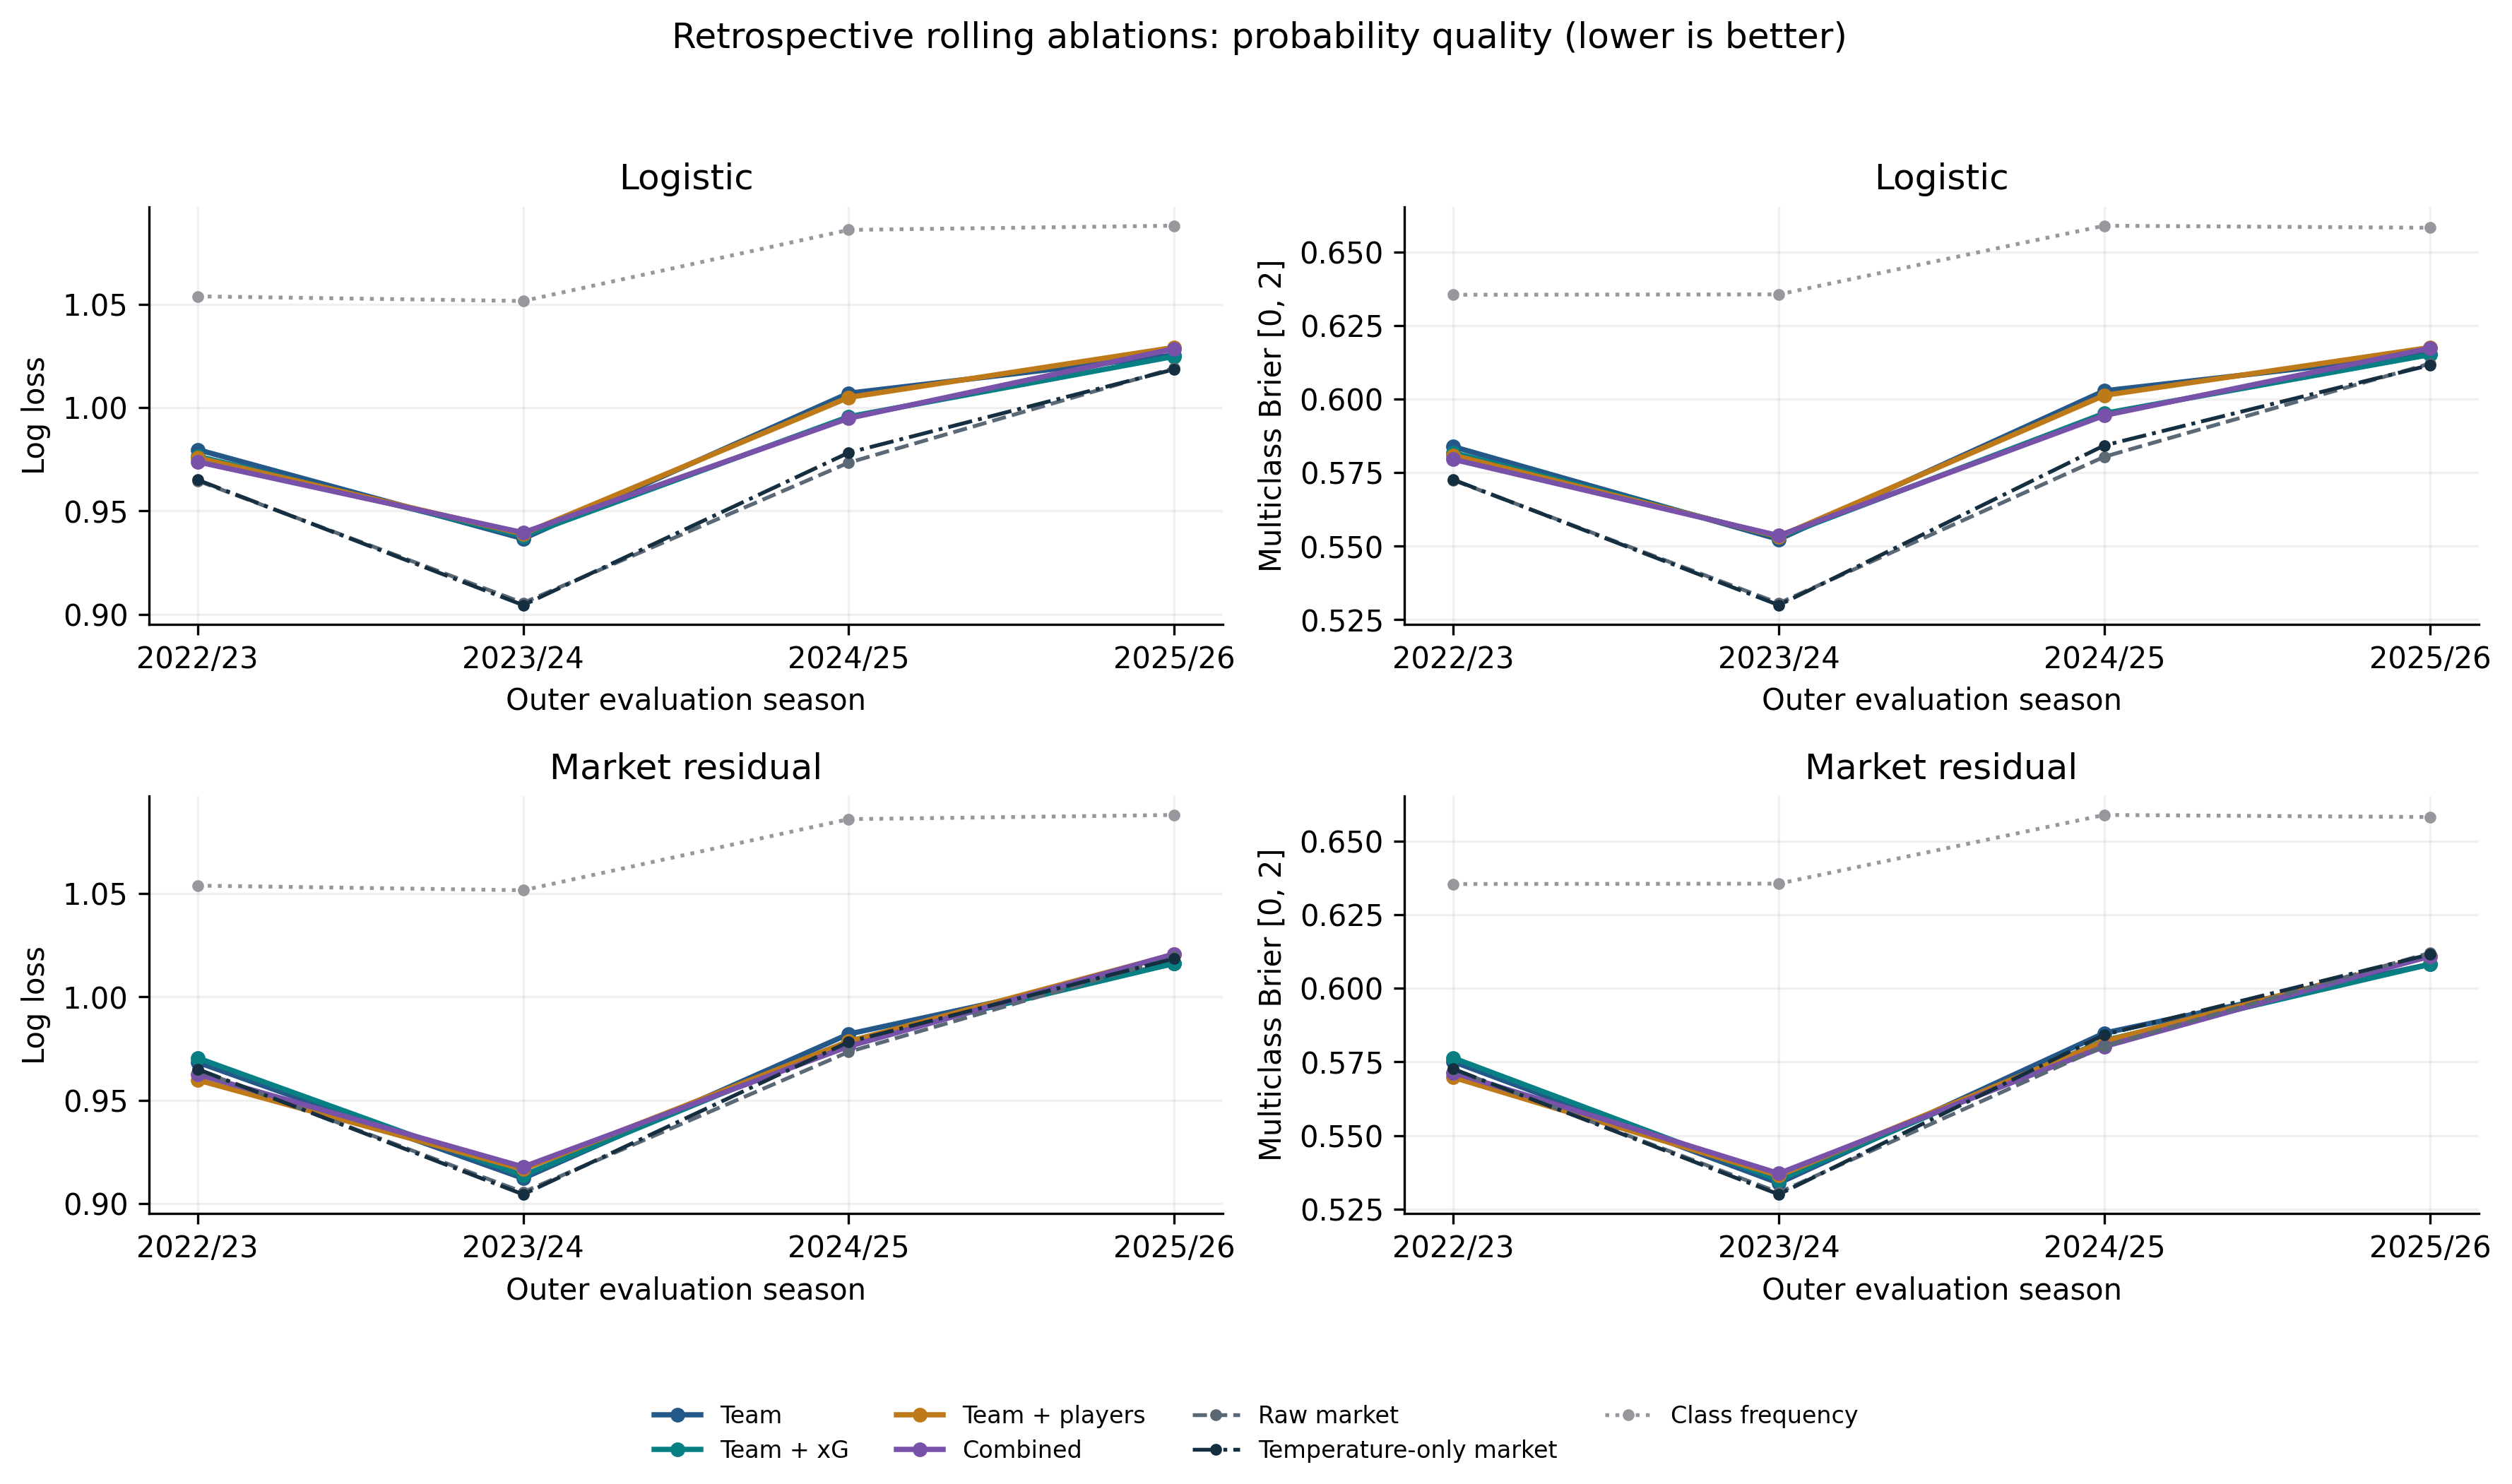

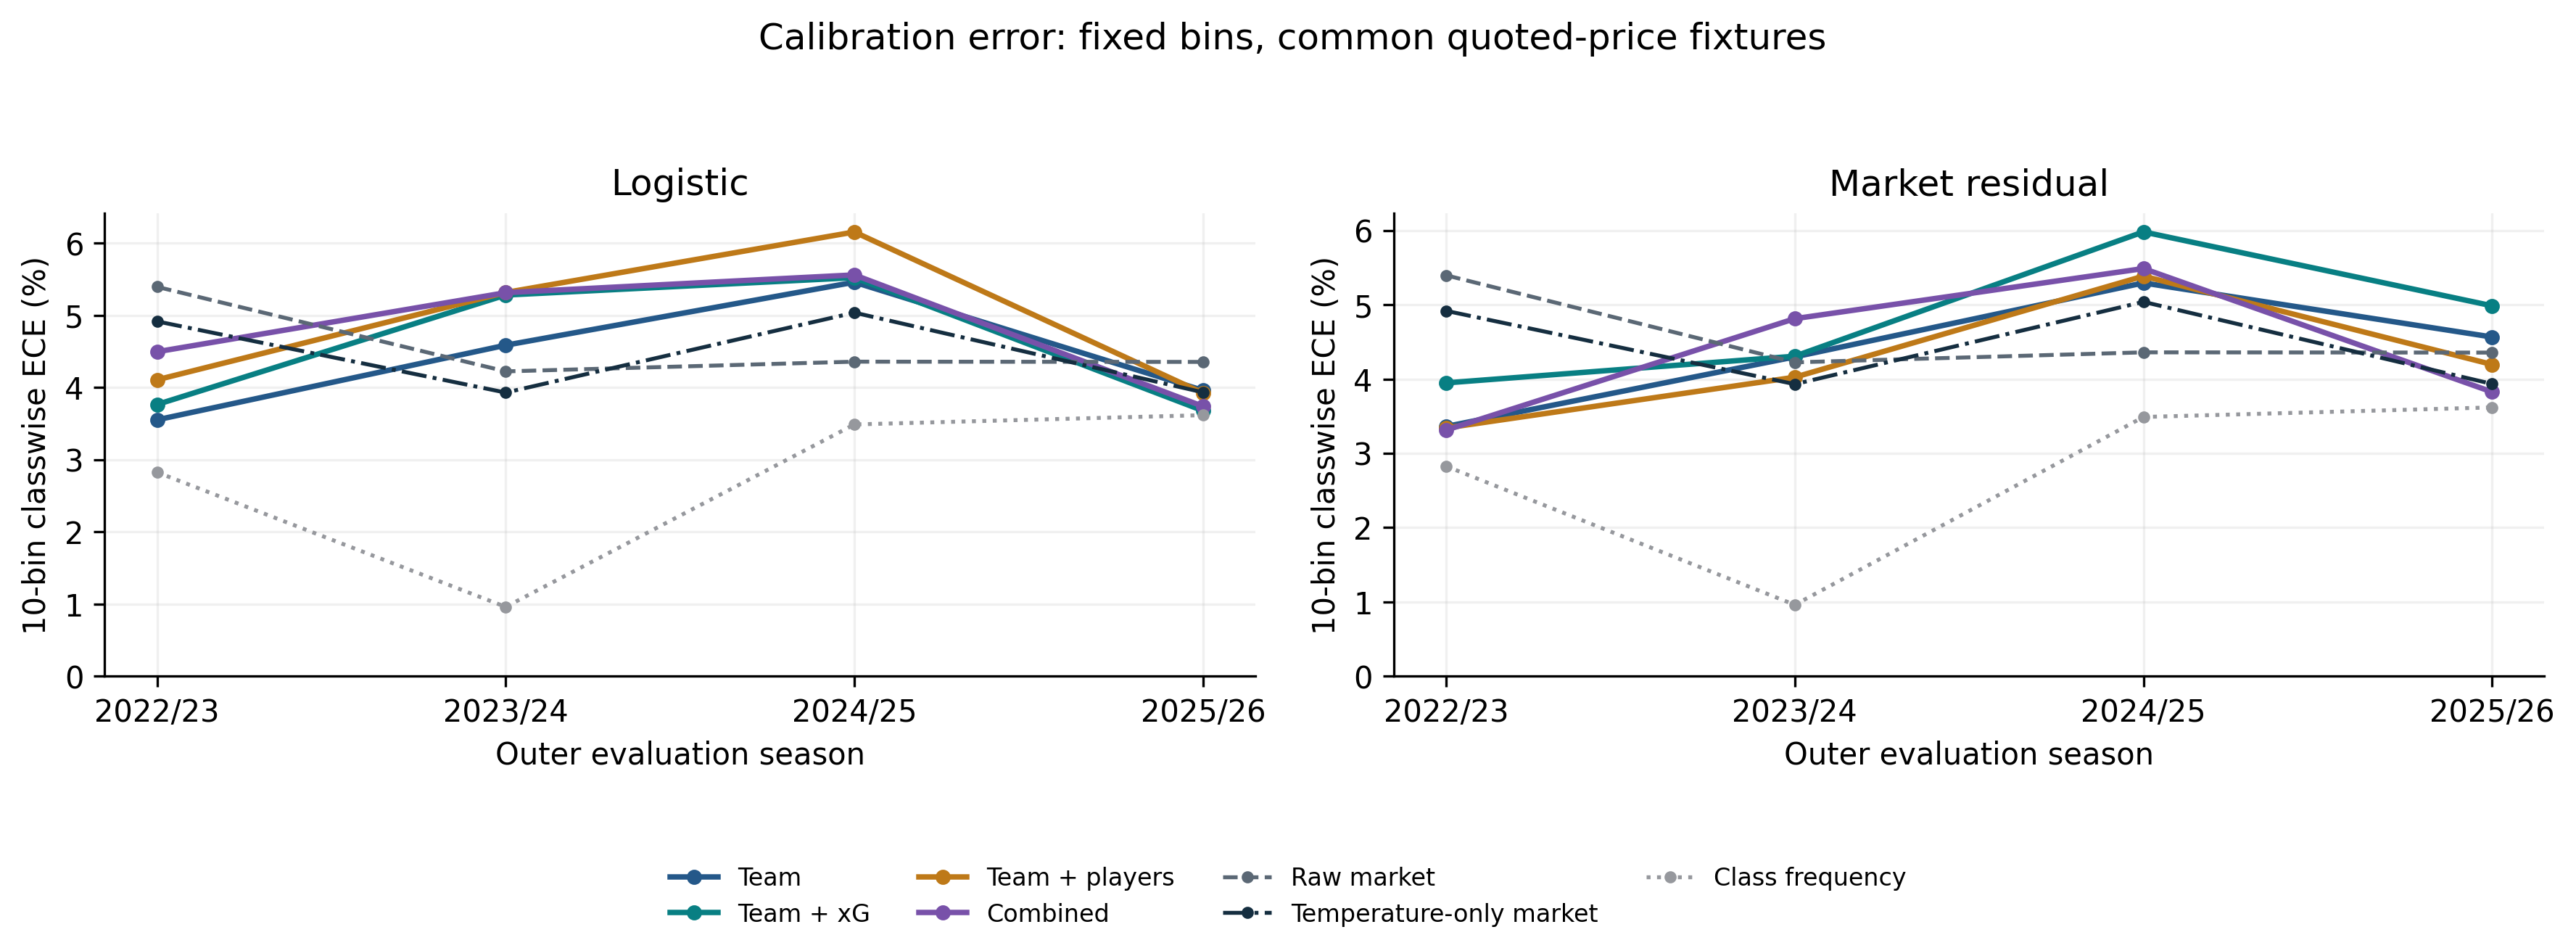

In [2]:
scores=table('classification_scores')
display(scores[scores['outer_season'].astype(str).eq('pooled')].sort_values(['scope','log_loss']))
display(Image(filename=str(RESULTS/'ablation_probability_quality.png')))
display(Image(filename=str(RESULTS/'ablation_calibration_error.png')))

## Incremental feature comparisons
Differences are candidate minus reference. Conditional date-bootstrap intervals omit fitting/selection uncertainty and are not adjusted for multiple comparisons. ECE comparisons are point estimates only.

,metric,difference,ci_lower,ci_upper,n_matches,n_bootstrap,ci_level,bootstrap_unit,outer_season,scope,feature_group,model_type,reference_group,reference_model_type
0,log_loss,0.021397,0.010666,0.033343,1470,1000,0.95,whole_match_date_stratified_by_outer_season,pooled,common_odds_matches,team,logistic,market_only,baseline
1,brier_score,0.014608,0.007329,0.021909,1470,1000,0.95,whole_match_date_stratified_by_outer_season,pooled,common_odds_matches,team,logistic,market_only,baseline
2,accuracy,-0.014966,-0.029354,-0.000646,1470,1000,0.95,whole_match_date_stratified_by_outer_season,pooled,common_odds_matches,team,logistic,market_only,baseline
3,log_loss,0.003980,-0.003113,0.011434,1470,1000,0.95,whole_match_date_stratified_by_outer_season,pooled,common_odds_matches,team,market_residual,market_only,baseline
4,brier_score,0.001553,-0.002963,0.005751,1470,1000,0.95,whole_match_date_stratified_by_outer_season,pooled,common_odds_matches,team,market_residual,market_only,baseline
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,brier_score,0.002690,0.000519,0.004922,767,1000,0.95,whole_match_date_stratified_by_outer_season,pooled,complete_source_history,market_only,market_temperature,market_only,baseline
116,accuracy,0.000000,0.000000,0.000000,767,1000,0.95,whole_match_date_stratified_by_outer_season,pooled,complete_source_history,market_only,market_temperature,market_only,baseline
117,log_loss,0.053098,0.028124,0.079172,767,1000,0.95,whole_match_date_stratified_by_outer_season,pooled,complete_source_history,class_frequency,baseline,market_only,baseline
118,brier_score,0.038066,0.020471,0.056630,767,1000,0.95,whole_match_date_stratified_by_outer_season,pooled,complete_source_history,class_frequency,baseline,market_only,baseline


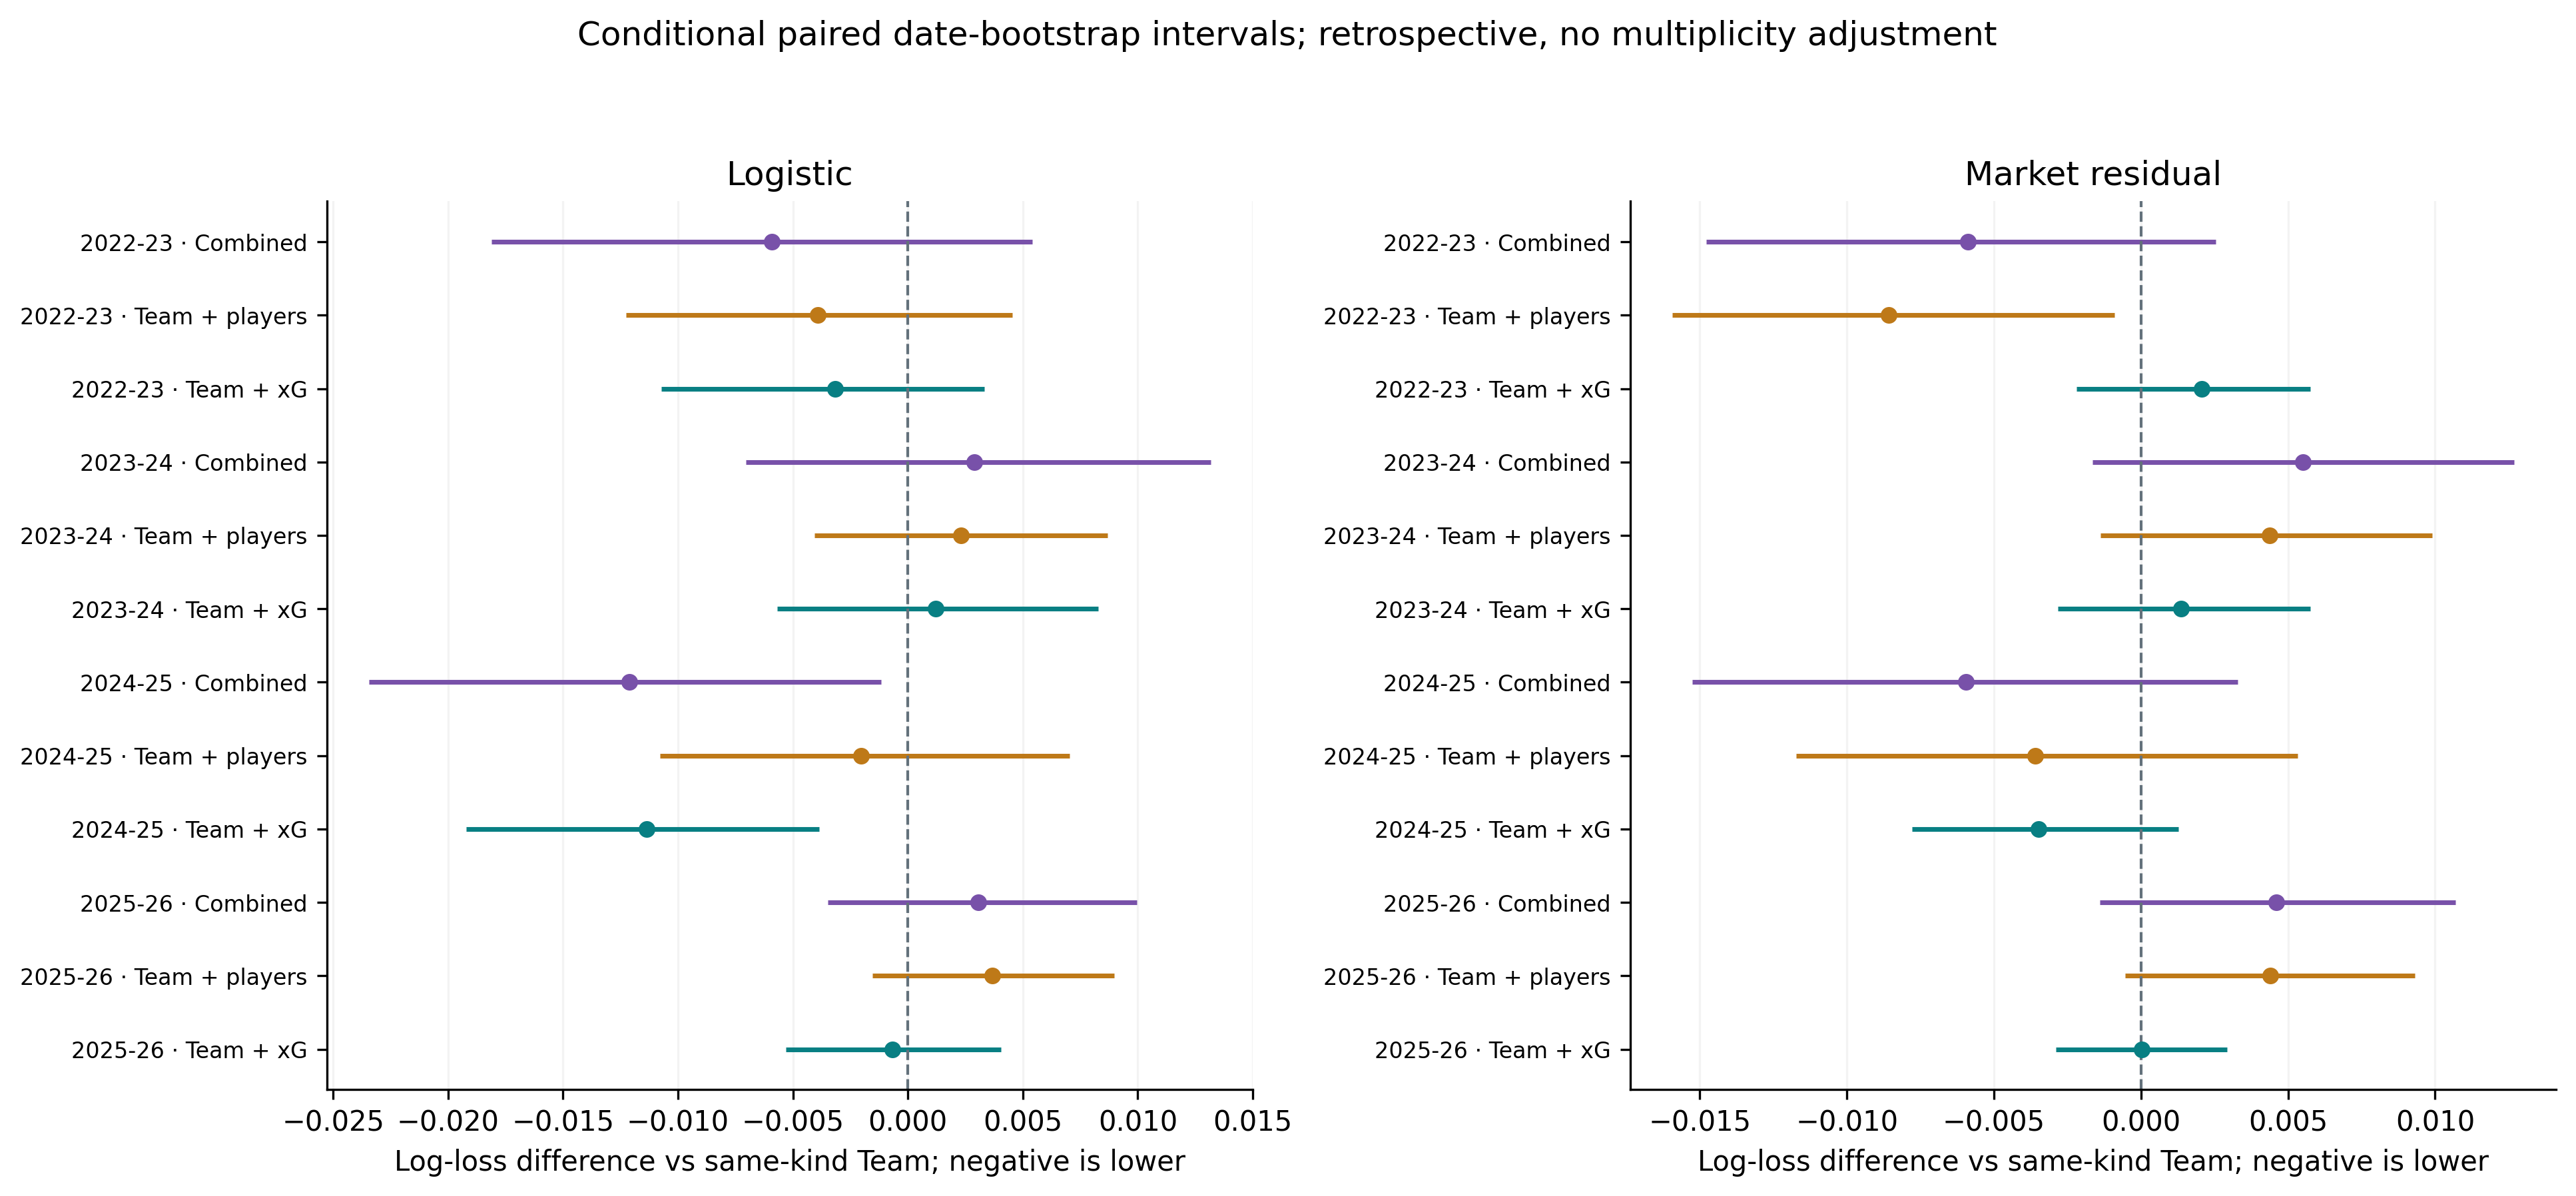

In [3]:
pairs=table('paired_comparisons')
display(pairs[pairs['outer_season'].astype(str).eq('pooled')].reset_index(drop=True))
display(Image(filename=str(RESULTS/'ablation_paired_logloss.png')))

## Same source-history intersection
Every variant shares the complete-history eligibility mask. Both clubs need at least eight observed xG and FPL slots in their ten earlier E0 matches and nonmissing fixed performance inputs. This is an evaluation sensitivity, not a refit.

,outer_season,scope,feature_group,model_type,n_matches,accuracy,classwise_ece_10,classwise_ece_5,classwise_ece_15,log_loss,brier_score
0,2022-23,complete_source_history,team,logistic,153,0.503268,0.066276,0.055217,0.080681,1.027356,0.615074
1,2022-23,complete_source_history,team,market_residual,153,0.516340,0.056856,0.049639,0.077564,1.016731,0.607788
2,2022-23,complete_source_history,team_xg,logistic,153,0.496732,0.070428,0.053254,0.077632,1.024253,0.614290
3,2022-23,complete_source_history,team_xg,market_residual,153,0.522876,0.060291,0.045960,0.075506,1.018622,0.609345
4,2022-23,complete_source_history,team_player,logistic,153,0.496732,0.064050,0.052953,0.070990,1.020513,0.610922
5,2022-23,complete_source_history,team_player,market_residual,153,0.516340,0.051408,0.046736,0.085692,1.001965,0.598657
6,2022-23,complete_source_history,combined,logistic,153,0.496732,0.060561,0.054111,0.085224,1.019065,0.610912
7,2022-23,complete_source_history,combined,market_residual,153,0.522876,0.055466,0.048209,0.078514,1.004491,0.600540
8,2022-23,complete_source_history,market_only,baseline,153,0.535948,0.058030,0.054235,0.080639,1.018870,0.610102
9,2022-23,complete_source_history,market_only,market_temperature,153,0.535948,0.065825,0.055711,0.084144,1.023663,0.612601


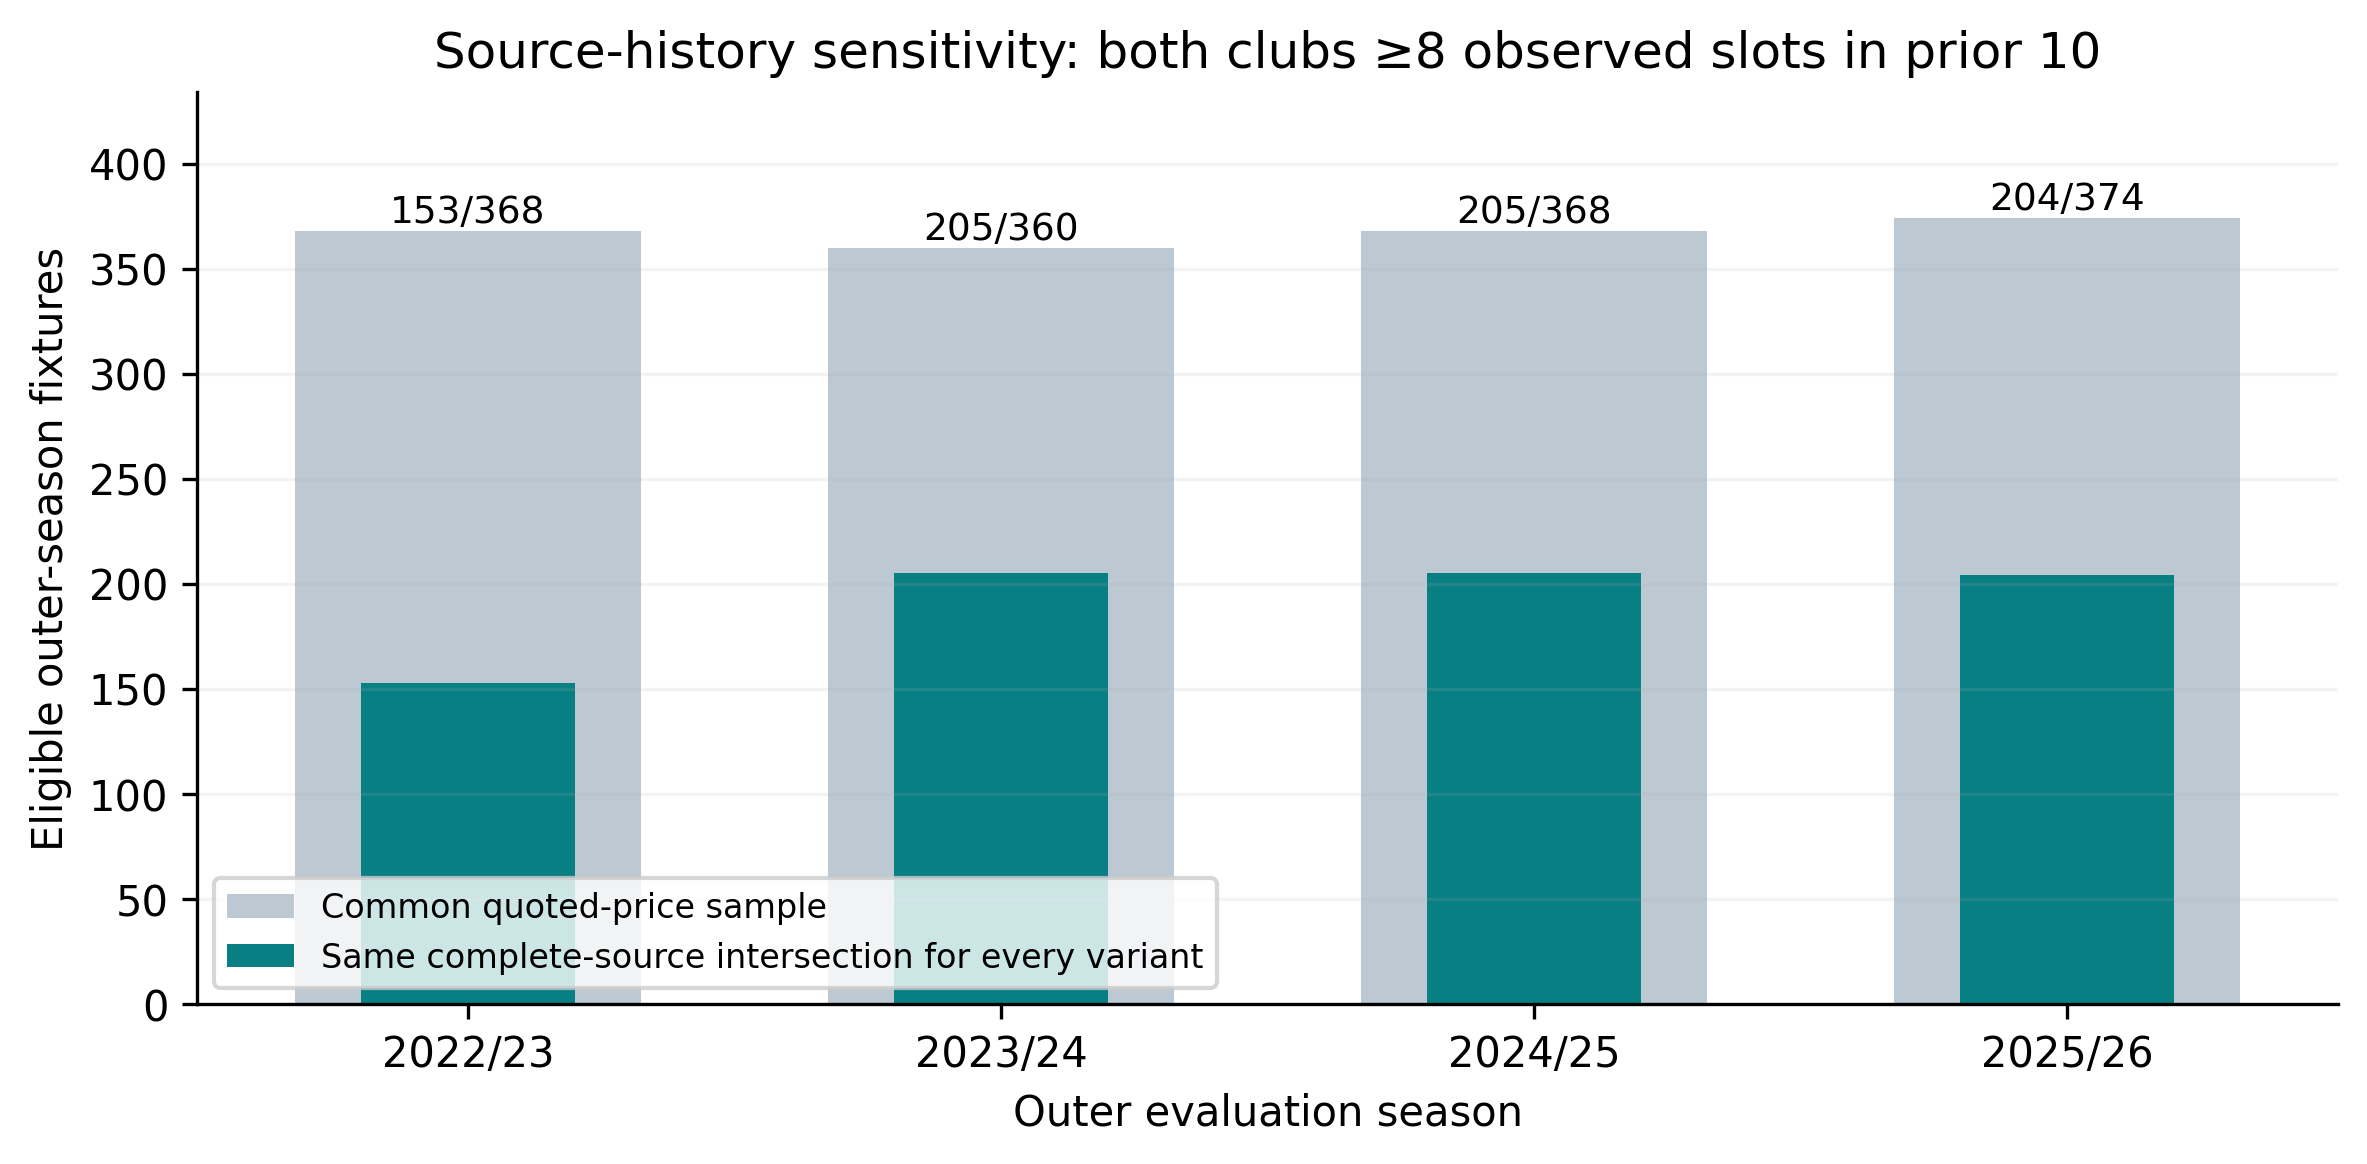

Full reconciliation fields: ['official_seasons_preferred', 'archive_rows_superseded_by_official_season', 'assistant_manager_rows_excluded', 'rows_returned', 'audit_rows', 'full_raw_e0_match_rows', 'missing_opponent_before', 'missing_opponent_repaired', 'eligible_player_rows', 'conflict_or_unresolved_rows', 'eligible_exact_fixtures', 'eligible_exact_fixture_club_pairs', 'quarantined_fpl_fixtures', 'independent_lookup', 'by_season', 'input_files_read', 'identity_method', 'no_source_writes', 'scores_or_performance_used_for_matching', 'policy', 'timing_limit']


{'team': ['feat_diff_std_goals_diff',
  'feat_diff_roll10_goals_diff',
  'feat_diff_std_shots_on_target_diff',
  'feat_diff_roll10_shots_on_target_diff',
  'feat_diff_std_corners_diff',
  'feat_diff_roll10_points',
  'feat_home_prior_season_win_pct',
  'feat_away_prior_season_win_pct',
  'feat_diff_rest_days',
  'feat_home_prior_season_missing',
  'feat_home_promoted_from_outside_epl',
  'feat_away_prior_season_missing',
  'feat_away_promoted_from_outside_epl',
  'feat_home_us_roll10_observed_matches',
  'feat_home_fpl_roll10_observed_matches',
  'feat_home_us_history_missing',
  'feat_home_fpl_history_missing',
  'feat_away_us_roll10_observed_matches',
  'feat_away_fpl_roll10_observed_matches',
  'feat_away_us_history_missing',
  'feat_away_fpl_history_missing'],
 'team_xg': ['feat_diff_std_goals_diff',
  'feat_diff_roll10_goals_diff',
  'feat_diff_std_shots_on_target_diff',
  'feat_diff_roll10_shots_on_target_diff',
  'feat_diff_std_corners_diff',
  'feat_diff_roll10_points',
  'feat

In [4]:
display(scores[scores['scope'].eq('complete_source_history')].reset_index(drop=True))
display(Image(filename=str(RESULTS/'ablation_history_coverage.png')))
source_audit=json.loads((RESULTS/'source_reconciliation_summary.json').read_text(encoding='utf-8'))
print('Full reconciliation fields:', list(source_audit))
groups=json.loads((RESULTS/'feature_groups.json').read_text(encoding='utf-8'))
display(groups)

## Fixed exploratory archived-price policies
The 5% expected-return threshold is not newly selected on these results. Fixed stakes and quarter Kelly (2% cap) are hypothetical. Capital resets per outer season. Empty ROI interval columns mean uncertainty was not estimated, not that returns are precise.

,outer_season,feature_group,model_type,staking,bet_count,profit,turnover,roi,roi_ci_low,roi_ci_high,max_drawdown
0,2022-23,team,logistic,fixed,291,188.200000,2910.000000,0.064674,None,None,0.125131
1,2022-23,team,logistic,kelly,291,-68.801864,3928.128135,-0.017515,None,None,0.264063
2,2022-23,team,market_residual,fixed,270,256.300000,2700.000000,0.094926,None,None,0.159580
3,2022-23,team,market_residual,kelly,270,285.864758,3950.860072,0.072355,None,None,0.144666
4,2022-23,team_xg,logistic,fixed,292,12.400000,2920.000000,0.004247,None,None,0.226480
...,...,...,...,...,...,...,...,...,...,...,...
83,2025-26,market_only,baseline,kelly,62,-110.654561,223.994329,-0.494006,None,None,0.139252
84,2025-26,market_only,market_temperature,fixed,91,-570.000000,910.000000,-0.626374,None,None,0.570000
85,2025-26,market_only,market_temperature,kelly,91,-191.630359,356.625516,-0.537343,None,None,0.212635
86,2025-26,class_frequency,baseline,fixed,368,-67.800000,3680.000000,-0.018424,None,None,0.327752


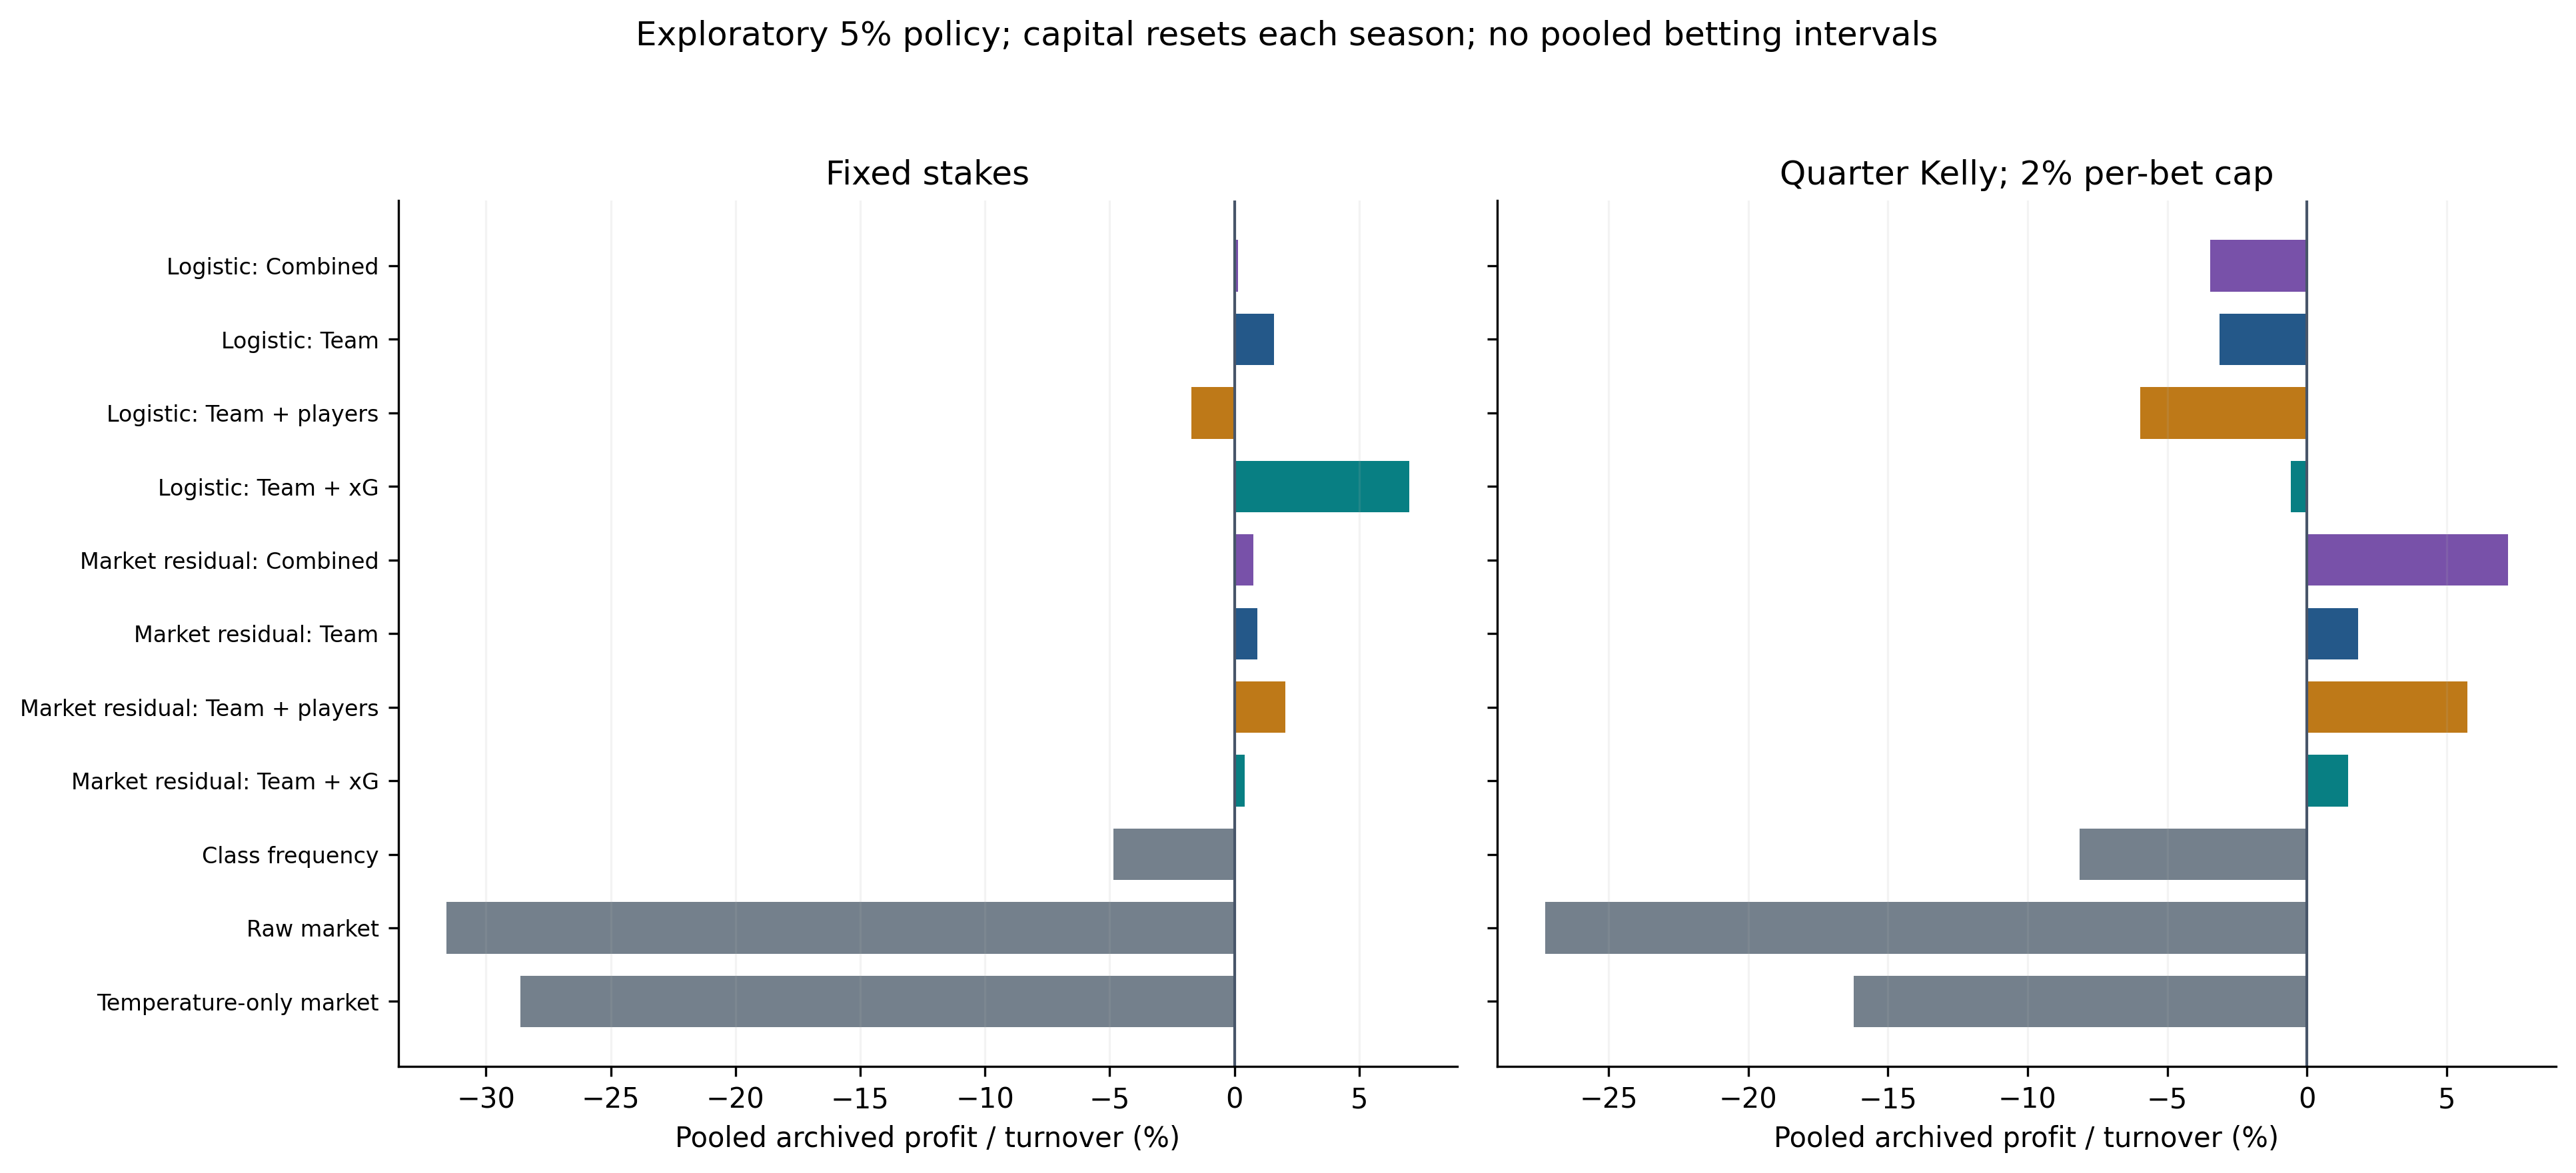

,match_id,match_date,season,result,complete_source_history,p_H,p_D,p_A,feature_group,model_type,outer_season
0,fd_bd1a15cb36c1e49d0ac584ea,2022-08-05,2022-23,A,False,0.349995,0.115857,0.534148,team,logistic,2022-23
1,fd_0b8fc455e974a70910b15c8b,2022-08-06,2022-23,H,False,0.370617,0.602199,0.027184,team,logistic,2022-23
2,fd_33c053c96fb6b2721862177e,2022-08-06,2022-23,H,False,0.340543,0.090167,0.569290,team,logistic,2022-23
3,fd_8661f3c362c9949e479ff8b8,2022-08-06,2022-23,D,False,0.244490,0.088688,0.666822,team,logistic,2022-23
4,fd_e4dab8242e6e4a4098db7a49,2022-08-06,2022-23,H,False,0.693959,0.078847,0.227195,team,logistic,2022-23
5,fd_ebc8c1e68be78615bdda3486,2022-08-06,2022-23,A,False,0.287127,0.148569,0.564304,team,logistic,2022-23
6,fd_f0502fb5962a05ff9881cbb6,2022-08-06,2022-23,H,False,0.371137,0.148984,0.479879,team,logistic,2022-23
7,fd_69b46364a81bc8e43b102447,2022-08-07,2022-23,D,False,0.380455,0.103455,0.516091,team,logistic,2022-23
8,fd_a3be665a85f654682b73fb65,2022-08-07,2022-23,A,False,0.241249,0.112460,0.646291,team,logistic,2022-23
9,fd_bd727dae483c3eb9bebfa612,2022-08-07,2022-23,A,False,0.420197,0.123315,0.456488,team,logistic,2022-23


In [5]:
betting=table('betting_summary')
display(betting[['outer_season','feature_group','model_type','staking','bet_count','profit','turnover','roi','roi_ci_low','roi_ci_high','max_drawdown']])
display(Image(filename=str(RESULTS/'ablation_betting_roi.png')))
display(table('predictions').head(12))

## Tuning audit and limits
Past outer seasons use earlier training/tuning/calibration roles. These chronological controls do not make already inspected history a new untouched test. No prospective predictions or live execution are established.

In [6]:
display(table('tuning_trials').head(30))
print('Run limitations:',metadata.get('limitations',[]))

,outer_season,feature_group,model_type,C,n_features,n_matches,accuracy,classwise_ece_10,classwise_ece_5,classwise_ece_15,log_loss,brier_score
0,2022-23,team,logistic,0.03,21,338,0.476331,0.086558,0.081103,0.086310,1.050496,0.622552
1,2022-23,team,logistic,0.30,21,338,0.482249,0.082385,0.080141,0.089324,1.054875,0.623406
2,2022-23,team,logistic,3.00,21,338,0.476331,0.083075,0.078081,0.092308,1.055988,0.623632
3,2022-23,team,market_residual,0.03,21,338,0.476331,0.074655,0.071616,0.078591,1.038194,0.615150
4,2022-23,team,market_residual,0.30,21,338,0.482249,0.072136,0.070462,0.077675,1.041471,0.616326
5,2022-23,team,market_residual,3.00,21,338,0.479290,0.081771,0.074644,0.080543,1.043566,0.617042
6,2022-23,team_xg,logistic,0.03,25,338,0.470414,0.084487,0.080859,0.092344,1.057293,0.627087
7,2022-23,team_xg,logistic,0.30,25,338,0.473373,0.085801,0.082653,0.098386,1.066813,0.630979
8,2022-23,team_xg,logistic,3.00,25,338,0.467456,0.086742,0.085798,0.096693,1.069645,0.632337
9,2022-23,team_xg,market_residual,0.03,25,338,0.470414,0.077829,0.075791,0.086535,1.039424,0.616621


Run limitations: ['2025/26 outcomes were inspected in the earlier study; this is exploratory historical research', 'All feature groups share source-coverage flags; team group is not independent of source availability metadata', 'FPL aggregates summarize earlier contributions, not prospectively known player availability', 'Current-club survivor bias, incomplete noncohort player histories, archival revisions and unverified quote clocks remain', 'Betting rules are fixed exploratory summaries, not freshly validated production policies']
